

# ES 335 Project — Fraud Job Posting Detection



In [ ]:

#IMPORTS

#Core data handling
import pandas as pd
import numpy as np

#Visualization (for EDA / plots report)
import matplotlib.pyplot as plt
import seaborn as sns

#Train/test splitting
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV

#Preprocessing
from sklearn.preprocessing import OneHotEncoder, LabelEncoder
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Feature importance / selection
from sklearn.feature_selection import mutual_info_classif, chi2

# Models
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier   # used for the baseline model

# Evaluation metrics
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    precision_recall_curve,
    roc_auc_score,
    average_precision_score,
    f1_score
)

#  Reproducibility
RANDOM_STATE = 42   # use this everywhere a random_state is needed, so results are reproducible

#  Display settings (optional, just makes printed tables easier to read)
pd.set_option('display.max_columns', None)
pd.set_option('display.width', None)

print("All libraries imported successfully.")

All libraries imported successfully.


In [ ]:
# CELL 2: LOAD THE DATASET
# Manually upload the CSV file (downloaded earlier from Kaggle)
# directly into this Colab session.

#Upload the CSV file from your computer
from google.colab import files
print("Please upload fake_job_postings.csv when prompted below:")
uploaded = files.upload()

#Load it into a pandas DataFrame
df = pd.read_csv("fake_job_postings.csv")

#Quick sanity check that it loaded correctly
print("Dataset shape (rows, columns):", df.shape)
df.sample(5)

Please upload fake_job_postings.csv when prompted below:


Saving fake_job_postings.csv to fake_job_postings.csv
Dataset shape (rows, columns): (17880, 18)


,job_id,title,location,department,salary_range,company_profile,description,requirements,benefits,telecommuting,has_company_logo,has_questions,employment_type,required_experience,required_education,industry,function,fraudulent
5089,5090,Senior Product Manager,"US, VA, Richmond",NaN,NaN,"We're artists, thinkers, and doers in an open,...",The Senior Product Manager works both individu...,Persistent and tenacious passion to understand...,NaN,0,1,0,Full-time,Mid-Senior level,Bachelor's Degree,Computer Software,Product Management,0
2811,2812,Broadcast Journalist,"US, FL, Miami",NaN,NaN,Applied Memetics LLC is a professional service...,The Broadcast Journalist shall properly comple...,The Broadcast Journalist shall perform service...,NaN,0,1,0,NaN,NaN,NaN,NaN,NaN,0
17202,17203,Java Developer,"US, DC, Washington",NaN,95000-105000,NaN,Our client is looking for qualified candidates...,Required Qualifications:- Minimum of ...,NaN,0,0,0,Contract,Associate,Bachelor's Degree,Computer Software,Information Technology,0
14651,14652,Sous Chef - Upscale Restaurant,"US, NJ, Hoboken",NaN,NaN,NaN,Strong Sous Chef (Executive Chef-ready) needed...,NaN,NaN,0,0,0,NaN,NaN,NaN,Restaurants,NaN,0
3712,3713,Entry Level with BBB A+ Company-Training Provi...,"US, TN, Knoxville",NaN,35000-65000,About ADS Security – Our Proud History in the ...,You are not going to find your perfect job unl...,Great AttitudeWill to SucceedPositivityStudent...,Entry Level-Training ProvidedCompany Issued iP...,0,1,1,Full-time,Entry level,High School or equivalent,Security and Investigations,Marketing,0


In [ ]:
df.shape

(17880, 18)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17880 entries, 0 to 17879
Data columns (total 18 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   job_id               17880 non-null  int64 
 1   title                17880 non-null  object
 2   location             17534 non-null  object
 3   department           6333 non-null   object
 4   salary_range         2868 non-null   object
 5   company_profile      14572 non-null  object
 6   description          17879 non-null  object
 7   requirements         15184 non-null  object
 8   benefits             10668 non-null  object
 9   telecommuting        17880 non-null  int64 
 10  has_company_logo     17880 non-null  int64 
 11  has_questions        17880 non-null  int64 
 12  employment_type      14409 non-null  object
 13  required_experience  10830 non-null  object
 14  required_education   9775 non-null   object
 15  industry             12977 non-null  object
 16  func

In [ ]:
df.isnull().sum()

,0
job_id,0
title,0
location,346
department,11547
salary_range,15012
company_profile,3308
description,1
requirements,2696
benefits,7212
telecommuting,0


In [ ]:
print("missing values in percentages:")
missing_pct = (df.isnull().sum()/len(df)*100).sort_values(ascending = False).round(2)
for col , pct in missing_pct.items():
  print(f"{col} : {pct}%")

missing values in percentages:
salary_range : 83.96%
department : 64.58%
required_education : 45.33%
benefits : 40.34%
required_experience : 39.43%
function : 36.1%
industry : 27.42%
employment_type : 19.41%
company_profile : 18.5%
requirements : 15.08%
location : 1.94%
description : 0.01%
title : 0.0%
job_id : 0.0%
telecommuting : 0.0%
has_questions : 0.0%
has_company_logo : 0.0%
fraudulent : 0.0%


In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
print("\nTarget column (fraudulent) counts:")
print(df['fraudulent'].value_counts())
print("\nTarget column (fraudulent) percentages:")
print((df['fraudulent'].value_counts(normalize=True) * 100).round(2))


Target column (fraudulent) counts:
fraudulent
0    17014
1      866
Name: count, dtype: int64

Target column (fraudulent) percentages:
fraudulent
0    95.16
1     4.84
Name: proportion, dtype: float64


In [ ]:
# Check for duplicate rows
print("\nExact duplicate rows (ignoring job_id):", df.drop(columns='job_id').duplicated().sum())


Exact duplicate rows (ignoring job_id): 281


In [ ]:
#***DUPLICATES AND LOCATIONS
#here we checked for number of rows having same title+description and same title+description+requirements

# Duplicate counts for the two possible keys
print("title+description:", df.duplicated(subset=['title', 'description']).sum())
print("title+description+requirements:", df.duplicated(subset=['title', 'description', 'requirements']).sum())

# Top countries (first part of the location string)
print(df['location'].str.split(',').str[0].value_counts().head(10))

title+description: 2093
title+description+requirements: 1932
location
US    10656
GB     2384
GR      940
CA      457
DE      383
NZ      333
IN      276
AU      214
PH      132
NL      127
Name: count, dtype: int64


In [ ]:
#REMOVE DUPLICATES

dup_key = ['title', 'description', 'requirements']

# Before: size and number of fraud rows
print("Before:", df.shape, "| fraud rows:", df['fraudulent'].sum())

# Do any duplicate groups have both fraud and genuine labels?
labels_per_group = df.groupby(dup_key, dropna=False)['fraudulent'].nunique()
print("Groups with conflicting labels:", (labels_per_group > 1).sum())

# Keep the first copy of each posting
df = df.drop_duplicates(subset=dup_key, keep='first')

# After: size, fraud rows and fraud rate
print("After:", df.shape, "| fraud rows:", df['fraudulent'].sum())
print("Fraud rate:", round(df['fraudulent'].mean() * 100, 2), "%")

#here we removed the duplicate

Before: (17880, 18) | fraud rows: 866
Groups with conflicting labels: 0
After: (15948, 18) | fraud rows: 688
Fraud rate: 4.31 %


In [ ]:
#CLEANING removing unwanted rows and columns and adding some columns

# Flag whether a company profile was given (before dropping the text)
df['has_company_profile'] = df['company_profile'].notnull().astype(int)

# Drop identifier and low-signal columns
df = df.drop(columns=['job_id', 'location', 'salary_range', 'department', 'benefits', 'telecommuting', 'company_profile'])

# Fill missing categories with 'Missing'
cat_cols = ['industry', 'function', 'required_education', 'required_experience', 'employment_type']
df[cat_cols] = df[cat_cols].fillna('Missing')

# Fill missing text with an empty string
text_cols = ['title', 'description', 'requirements']
df[text_cols] = df[text_cols].fillna('')

# Combine text fields into one column for TF-IDF
df['text_blob'] = df['title'] + ' ' + df['description'] + ' ' + df['requirements']

# Checks: no missing values, expected shape, fraud rate
print("Missing values left:", df.isnull().sum().sum())
print("Shape:", df.shape)
print("Fraud rate:", round(df['fraudulent'].mean() * 100, 2), "%")
print(df.columns.tolist())

Missing values left: 0
Shape: (15948, 13)
Fraud rate: 4.31 %
['title', 'description', 'requirements', 'has_company_logo', 'has_questions', 'employment_type', 'required_experience', 'required_education', 'industry', 'function', 'fraudulent', 'has_company_profile', 'text_blob']


In [ ]:
# CELL 5: TRAIN/TEST SPLIT

# Model inputs: combined text, 5 category columns, 3 flags
feature_cols = ['text_blob', 'industry', 'function', 'required_education', 'required_experience', 'employment_type', 'has_company_logo', 'has_questions', 'has_company_profile']
X = df[feature_cols]
y = df['fraudulent']

# Stratified 80/20 split with a fixed seed
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

# Check sizes, fraud counts and fraud rates
print("Train:", X_train.shape, "| fraud rows:", y_train.sum(), "| rate:", round(y_train.mean() * 100, 2), "%")
print("Test:", X_test.shape, "| fraud rows:", y_test.sum(), "| rate:", round(y_test.mean() * 100, 2), "%")

Train: (12758, 9) | fraud rows: 550 | rate: 4.31 %
Test: (3190, 9) | fraud rows: 138 | rate: 4.33 %


In [ ]:
#PREPROCESSING RECIPE AND BASELINE
import warnings
from sklearn.model_selection import cross_validate
warnings.filterwarnings('ignore')

# Column groups
text_col = 'text_blob'
cat_cols = ['industry', 'function', 'required_education', 'required_experience', 'employment_type']
flag_cols = ['has_company_logo', 'has_questions', 'has_company_profile']

# Recipe: TF-IDF on text, one-hot on categories, flags passed through (defined now, fit later inside pipelines)
preprocessor = ColumnTransformer([
    ('text', TfidfVectorizer(max_features=5000, stop_words='english', min_df=5), text_col),
    ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols),
    ('flags', 'passthrough', flag_cols),
])

# Same stratified 5-fold CV for every model
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = ['accuracy', 'precision', 'recall', 'f1', 'average_precision', 'roc_auc']

# Baseline: always predict 'not fraud' (it ignores its inputs, so one numeric column is enough)
baseline = DummyClassifier(strategy='most_frequent')
res = cross_validate(baseline, X_train[['has_company_logo']], y_train, cv=cv, scoring=scoring)

# Mean and spread across the 5 folds
for m in scoring:
    print(m, round(res['test_' + m].mean(), 3), '+/-', round(res['test_' + m].std(), 3))

accuracy 0.957 +/- 0.0
precision 0.0 +/- 0.0
recall 0.0 +/- 0.0
f1 0.0 +/- 0.0
average_precision 0.043 +/- 0.0
roc_auc 0.5 +/- 0.0


In [ ]:
#FEATURE IMPORTANCE ON TRAINING DATA ONLY
from sklearn.preprocessing import OrdinalEncoder

# Turn categories into integer codes (fine for a quick importance check)
struct_cols = cat_cols + flag_cols
Xs = X_train[struct_cols].copy()
Xs[cat_cols] = OrdinalEncoder().fit_transform(Xs[cat_cols])

# Mutual information with the target
mi = mutual_info_classif(Xs, y_train, discrete_features=True, random_state=RANDOM_STATE)
print(pd.Series(mi, index=struct_cols).sort_values(ascending=False).round(4))

# Random Forest importance
rf = RandomForestClassifier(n_estimators=200, class_weight='balanced', random_state=RANDOM_STATE).fit(Xs, y_train)
print(pd.Series(rf.feature_importances_, index=struct_cols).sort_values(ascending=False).round(4))

# Words most linked to fraud (chi-square on TF-IDF)
tfidf = TfidfVectorizer(max_features=3000, stop_words='english', min_df=5)
Xt = tfidf.fit_transform(X_train['text_blob'])
chi, _ = chi2(Xt, y_train)
print(pd.Series(chi, index=tfidf.get_feature_names_out()).sort_values(ascending=False).head(20).round(1))

industry               0.0290
has_company_profile    0.0251
has_company_logo       0.0229
function               0.0133
required_education     0.0066
required_experience    0.0046
has_questions          0.0029
employment_type        0.0017
dtype: float64
industry               0.2181
has_company_profile    0.1755
function               0.1640
has_company_logo       0.1444
required_education     0.1128
required_experience    0.0949
employment_type        0.0478
has_questions          0.0424
dtype: float64
subsea            150.3
aker              144.0
hse                91.2
cash               66.0
earn               65.7
entry              58.9
oil                57.4
gas                55.7
administrative     44.8
clerical           41.4
petroleum          37.0
clerk              36.0
offshore           35.7
typing             35.6
minutes            27.1
assistant          25.6
receptionist       24.9
rn                 24.2
info               22.3
home               20.1
dtype: flo

In [ ]:
# IMPORTANCE OF DROPPED COLUMNS (TRAINING ROWS ONLY)

# Reload the raw file and keep only the rows that are in X_train
from sklearn.preprocessing import OrdinalEncoder
raw = pd.read_csv("fake_job_postings.csv")
r = raw.loc[X_train.index]

# Build simple versions of the dropped columns
chk = pd.DataFrame({
    'has_salary': r['salary_range'].notnull().astype(int),
    'has_department': r['department'].notnull().astype(int),
    'has_benefits': r['benefits'].notnull().astype(int),
    'telecommuting': r['telecommuting'],
})

# Country code from location, turned into integer codes
country = r['location'].str.split(',').str[0].fillna('Missing')
chk['country'] = OrdinalEncoder().fit_transform(country.to_frame()).ravel()

# Mutual information with the target, training rows only
mi2 = mutual_info_classif(chk, y_train, discrete_features=True, random_state=RANDOM_STATE)
print(pd.Series(mi2, index=chk.columns).sort_values(ascending=False).round(4))

country           0.0182
has_salary        0.0017
telecommuting     0.0006
has_benefits      0.0002
has_department    0.0000
dtype: float64


In [ ]:
# LOGISTIC REGRESSION WITH TUNING

# Pipeline: preprocessing + model together, so TF-IDF and encoders are fit on training folds only
lr_pipe = Pipeline([
    ('prep', preprocessor),
    ('clf', LogisticRegression(class_weight='balanced', solver='liblinear', max_iter=1000, random_state=RANDOM_STATE)),
])

# Settings to try: L1 or L2 penalty, five strengths
param_grid = {
    'clf__penalty': ['l1', 'l2'],
    'clf__C': [0.01, 0.1, 1, 10, 100],
}

# Try all 10 combinations with the same 5-fold CV, scored by PR-AUC
grid = GridSearchCV(lr_pipe, param_grid, cv=cv, scoring='average_precision', n_jobs=-1)
grid.fit(X_train, y_train)

# All 10 combinations, best first
res_lr = pd.DataFrame(grid.cv_results_)[['param_clf__penalty', 'param_clf__C', 'mean_test_score', 'std_test_score']]
print(res_lr.sort_values('mean_test_score', ascending=False).round(3))
print("Best settings:", grid.best_params_)

# Full metrics for the best setting, mean and spread across folds
best_res = cross_validate(grid.best_estimator_, X_train, y_train, cv=cv, scoring=scoring)
for m in scoring:
    print(m, round(best_res['test_' + m].mean(), 3), '+/-', round(best_res['test_' + m].std(), 3))

  param_clf__penalty  param_clf__C  mean_test_score  std_test_score
7                 l2         10.00            0.711           0.033
9                 l2        100.00            0.706           0.023
5                 l2          1.00            0.658           0.051
6                 l1         10.00            0.649           0.030
8                 l1        100.00            0.642           0.033
4                 l1          1.00            0.600           0.057
3                 l2          0.10            0.520           0.051
1                 l2          0.01            0.435           0.049
2                 l1          0.10            0.415           0.045
0                 l1          0.01            0.312           0.044
Best settings: {'clf__C': 10, 'clf__penalty': 'l2'}
accuracy 0.965 +/- 0.004
precision 0.58 +/- 0.049
recall 0.731 +/- 0.027
f1 0.646 +/- 0.034
average_precision 0.711 +/- 0.033
roc_auc 0.955 +/- 0.003


In [19]:
# FINAL TEST EVALUATION (run once)
from sklearn.metrics import accuracy_score, precision_score, recall_score

# Final model: tuned logistic regression, already refit on all training data
final_model = grid.best_estimator_

# Baseline fitted on training data
base = DummyClassifier(strategy='most_frequent').fit(X_train[['has_company_logo']], y_train)

# Predictions and fraud scores on the test set
pred = final_model.predict(X_test)
proba = final_model.predict_proba(X_test)[:, 1]
base_pred = base.predict(X_test[['has_company_logo']])
base_proba = base.predict_proba(X_test[['has_company_logo']])[:, 1]

# Results table: baseline vs final model
rows = {
    'accuracy': (accuracy_score(y_test, base_pred), accuracy_score(y_test, pred)),
    'precision': (precision_score(y_test, base_pred, zero_division=0), precision_score(y_test, pred)),
    'recall': (recall_score(y_test, base_pred), recall_score(y_test, pred)),
    'f1': (f1_score(y_test, base_pred), f1_score(y_test, pred)),
    'PR-AUC': (average_precision_score(y_test, base_proba), average_precision_score(y_test, proba)),
    'ROC-AUC': (roc_auc_score(y_test, base_proba), roc_auc_score(y_test, proba)),
}
print(pd.DataFrame(rows, index=['baseline', 'logistic regression']).T.round(3))

# Confusion matrix and per-class report
print(confusion_matrix(y_test, pred))
print(classification_report(y_test, pred, target_names=['genuine', 'fraud']))

           baseline  logistic regression
accuracy      0.957                0.970
precision     0.000                0.612
recall        0.000                0.812
f1            0.000                0.698
PR-AUC        0.043                0.806
ROC-AUC       0.500                0.976
[[2981   71]
 [  26  112]]
              precision    recall  f1-score   support

     genuine       0.99      0.98      0.98      3052
       fraud       0.61      0.81      0.70       138

    accuracy                           0.97      3190
   macro avg       0.80      0.89      0.84      3190
weighted avg       0.97      0.97      0.97      3190



precision 95% interval: 0.537 to 0.677
recall 95% interval: 0.746 to 0.874
f1 95% interval: 0.636 to 0.748
PR-AUC 95% interval: 0.743 to 0.857


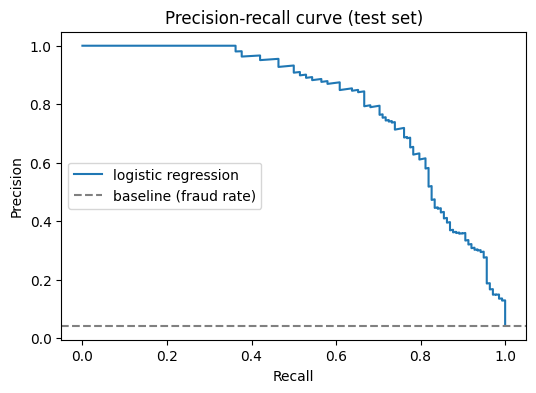

   threshold  precision  recall  flagged
0        0.2      0.382   0.870      314
1        0.3      0.453   0.833      254
2        0.4      0.531   0.819      213
3        0.5      0.612   0.812      183
4        0.6      0.677   0.775      158
5        0.7      0.739   0.739      138
6        0.8      0.790   0.681      119
scikit-learn version: 1.6.1


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [20]:
# BOOTSTRAP INTERVALS, PR CURVE, THRESHOLDS, SAVE MODEL
import joblib
import sklearn

# Resample the test set 1000 times to see how much the scores could vary
rng = np.random.RandomState(RANDOM_STATE)
y_arr = y_test.to_numpy()
boot = {'precision': [], 'recall': [], 'f1': [], 'PR-AUC': []}
for _ in range(1000):
    idx = rng.randint(0, len(y_arr), len(y_arr))
    yt, pp, ps = y_arr[idx], pred[idx], proba[idx]
    boot['precision'].append(precision_score(yt, pp, zero_division=0))
    boot['recall'].append(recall_score(yt, pp))
    boot['f1'].append(f1_score(yt, pp))
    boot['PR-AUC'].append(average_precision_score(yt, ps))
for k, v in boot.items():
    print(k, '95% interval:', round(np.percentile(v, 2.5), 3), 'to', round(np.percentile(v, 97.5), 3))

# Precision-recall curve with the baseline level
prec, rec, thr = precision_recall_curve(y_test, proba)
plt.figure(figsize=(6, 4))
plt.plot(rec, prec, label='logistic regression')
plt.axhline(y_test.mean(), color='gray', linestyle='--', label='baseline (fraud rate)')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-recall curve (test set)')
plt.legend()
plt.show()

# How precision and recall change with the decision threshold
rows_t = []
for t in [0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8]:
    p_t = (proba >= t).astype(int)
    rows_t.append([t, precision_score(y_test, p_t, zero_division=0), recall_score(y_test, p_t), int(p_t.sum())])
print(pd.DataFrame(rows_t, columns=['threshold', 'precision', 'recall', 'flagged']).round(3))

# Save the model and test scores for the website
print('scikit-learn version:', sklearn.__version__)
joblib.dump(final_model, 'fraud_model.joblib')
pd.DataFrame({'y_true': y_test.to_numpy(), 'score': proba}).to_csv('test_scores.csv', index=False)
from google.colab import files
files.download('fraud_model.joblib')
files.download('test_scores.csv')

In [21]:
# ERROR ANALYSIS AND MODEL WORDS

# Test postings with true label, prediction and fraud score
errs = X_test.copy()
errs['y_true'] = y_test.to_numpy()
errs['pred'] = pred
errs['score'] = proba
errs['title'] = df.loc[X_test.index, 'title']

# False positives: genuine postings flagged as fraud, highest score first
fp = errs[(errs.y_true == 0) & (errs.pred == 1)].sort_values('score', ascending=False)
print("False positives:", len(fp))
print(fp[['title', 'industry', 'has_company_logo', 'has_company_profile', 'score']].head(10).round(2))

# False negatives: fraud postings the model missed, lowest score first
fn = errs[(errs.y_true == 1) & (errs.pred == 0)].sort_values('score')
print("False negatives:", len(fn))
print(fn[['title', 'industry', 'has_company_logo', 'has_company_profile', 'score']].head(10).round(2))

# Features with the largest weights in the final model
names = final_model.named_steps['prep'].get_feature_names_out()
coefs = pd.Series(final_model.named_steps['clf'].coef_[0], index=names)
print("Pushes towards FRAUD:")
print(coefs.sort_values(ascending=False).head(15).round(2))
print("Pushes towards GENUINE:")
print(coefs.sort_values().head(15).round(2))

False positives: 71
                                                   title  \
969                                      Human Resources   
13152                 COMEDY TICKET SALES REPRESENTATIVE   
5116   Business Analyst (Application Development Proc...   
4699               Experienced Sales/ Marketing Managers   
7897                  Executive Administrative Assistant   
4927                                  Associate Manager    
5734                     Part Time Ground representative   
15836                                 eBay Sales Manager   
7396                        Senior Lease Records Analyst   
5306           Administrative Assistant/Front Desk Clerk   

                              industry  has_company_logo  has_company_profile  \
969                    Human Resources                 0                    0   
13152        Marketing and Advertising                 0                    0   
5116   Business Supplies and Equipment                 0                    